# Pose: annotation set + zero-shot comparison
Part A builds the frames and model proposals to correct in CVAT (see `docs/POSE_ANNOTATION_GUIDE.md`). Part B (after correction) compares models on the hand-corrected `real_val` frames. Nothing here trains a model.


## A1. Mount Drive and install

In [17]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/pose_tools
!pip -q install onnxruntime-gpu huggingface_hub ultralytics

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## A2. Write the tools (generated from `python_scripts/pose/`)

In [18]:
%%writefile /content/pose_tools/pose_common.py
"""Shared helpers for the pose proposal / zero-shot tools (no project imports).

Top-down model contract (from the ViTPose-L SwimXYZ model card): input (N, 3, 256, 192) float32,
ImageNet-normalised RGB crop; output (N, 17, 64, 48) heatmaps in COCO-17 order.
Pure-numpy parts (box->crop parameters, heatmap decoding, PCK) are testable without weights.
"""
from __future__ import annotations

import math
from typing import Any

import numpy as np

COCO17 = ["nose", "left_eye", "right_eye", "left_ear", "right_ear", "left_shoulder", "right_shoulder",
          "left_elbow", "right_elbow", "left_wrist", "right_wrist", "left_hip", "right_hip",
          "left_knee", "right_knee", "left_ankle", "right_ankle"]
UPPER_BODY = [0, 5, 6, 7, 8, 9, 10]  # nose, shoulders, elbows, wrists
COCO_SKELETON = [[16, 14], [14, 12], [17, 15], [15, 13], [12, 13], [6, 12], [7, 13], [6, 7], [6, 8],
                 [7, 9], [8, 10], [9, 11], [2, 3], [1, 2], [1, 3], [2, 4], [3, 5], [4, 6], [5, 7]]
IN_W, IN_H = 192, 256
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def crop_params(box_xyxy: tuple[float, float, float, float], scale: float = 1.25) -> tuple[float, float, float]:
    """Return (x0, y0, s) of the crop window: window covers IN_W/s x IN_H/s pixels, box centred, padded."""
    x1, y1, x2, y2 = box_xyxy
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    bw, bh = max(x2 - x1, 1.0) * scale, max(y2 - y1, 1.0) * scale
    if bw / bh > IN_W / IN_H:
        bh = bw * IN_H / IN_W
    else:
        bw = bh * IN_W / IN_H
    s = IN_W / bw
    return cx - bw / 2, cy - bh / 2, s


def preprocess(frame_bgr: np.ndarray, box_xyxy: tuple[float, float, float, float]
               ) -> tuple[np.ndarray, tuple[float, float, float]]:
    import cv2  # lazy: Colab has it

    x0, y0, s = crop_params(box_xyxy)
    m = np.array([[s, 0, -x0 * s], [0, s, -y0 * s]], dtype=np.float32)
    crop = cv2.warpAffine(frame_bgr, m, (IN_W, IN_H), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))
    rgb = crop[:, :, ::-1].astype(np.float32) / 255.0
    rgb = (rgb - MEAN) / STD
    return rgb.transpose(2, 0, 1)[None], (x0, y0, s)


def decode_heatmaps(hm: np.ndarray, params: tuple[float, float, float]) -> np.ndarray:
    """hm: (17, H, W) -> (17, 3) [x, y, score] in image pixels (argmax, +quarter-pixel shift)."""
    k, h, w = hm.shape
    x0, y0, s = params
    out = np.zeros((k, 3), dtype=np.float32)
    for i in range(k):
        flat = int(np.argmax(hm[i]))
        iy, ix = divmod(flat, w)
        score = float(hm[i, iy, ix])
        fx, fy = float(ix), float(iy)
        if 0 < ix < w - 1:
            fx += 0.25 * np.sign(hm[i, iy, ix + 1] - hm[i, iy, ix - 1])
        if 0 < iy < h - 1:
            fy += 0.25 * np.sign(hm[i, iy + 1, ix] - hm[i, iy - 1, ix])
        cx, cy = (fx + 0.5) * IN_W / w, (fy + 0.5) * IN_H / h  # crop pixels
        out[i] = (cx / s + x0, cy / s + y0, score)
    return out


class OnnxVitPose:
    """Top-down ONNX pose model (ViTPose-L SwimXYZ export). Input name is read from the graph."""

    def __init__(self, path: str, providers: list[str] | None = None) -> None:
        import onnxruntime as ort

        self.sess = ort.InferenceSession(path, providers=providers or ["CUDAExecutionProvider",
                                                                         "CPUExecutionProvider"])
        self.input_name = self.sess.get_inputs()[0].name

    def predict(self, frame_bgr: np.ndarray, boxes: list[tuple[float, float, float, float]]) -> list[np.ndarray]:
        res = []
        for b in boxes:
            x, params = preprocess(frame_bgr, b)
            hm = self.sess.run(None, {self.input_name: x})[0][0]
            res.append(decode_heatmaps(hm, params))
        return res


def iou(a: tuple[float, ...], b: tuple[float, ...]) -> float:
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def pck(pred: np.ndarray, gt: np.ndarray, box_xyxy: tuple[float, ...], thr: float,
        idx: list[int] | None = None) -> tuple[int, int]:
    """(correct, total) over GT keypoints with visibility > 0. Normaliser: longer side of the GT box."""
    norm = max(box_xyxy[2] - box_xyxy[0], box_xyxy[3] - box_xyxy[1], 1.0)
    ok = tot = 0
    for i in idx if idx is not None else range(len(gt)):
        if gt[i][2] <= 0:
            continue
        tot += 1
        if math.hypot(pred[i][0] - gt[i][0], pred[i][1] - gt[i][1]) <= thr * norm:
            ok += 1
    return ok, tot


def confident_upper(pred: np.ndarray, min_conf: float = 0.5) -> int:
    return int(sum(1 for i in UPPER_BODY if pred[i][2] >= min_conf))


def as_info(**kw: Any) -> dict[str, Any]:
    return kw


Writing /content/pose_tools/pose_common.py


In [19]:
%%writefile /content/pose_tools/select_annotation_frames.py
"""Pick frames to annotate with keypoints, split by contiguous frame-index BLOCKS (no video ids exist).

Source: a YOLO detection dataset (images/{train,val}, labels/{train,val}), e.g. `datasets (1).zip` unzipped.
Source train/val folders are ignored (they overlap in frame index, so they leak): all frames are pooled,
cut into blocks of --block frames, whole blocks go to real_val or real_train, and frames within --buffer of a
block boundary that touches a block of the OTHER split are dropped. Class labels are NOT used or exported.

Writes into --out: images/ (copies), manifest.csv (image,split,block,frame,x1,y1,x2,y2).
"""
from __future__ import annotations

import argparse
import csv
import random
import re
import shutil
from pathlib import Path


def frame_index(p: Path) -> int | None:
    m = re.search(r"(\d+)$", p.stem)
    return int(m.group(1)) if m else None


def read_box(label: Path, w: int, h: int) -> tuple[float, float, float, float] | None:
    boxes = []
    for ln in label.read_text(errors="replace").splitlines():
        t = ln.split()
        if len(t) == 5:
            cx, cy, bw, bh = (float(v) for v in t[1:])
            boxes.append(((cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h))
    return boxes[0] if len(boxes) == 1 else None  # skip images with 0 or >1 boxes (unambiguous only)


def select(root: Path, n_val: int, n_train: int, block: int, buffer: int, spacing: int, seed: int
           ) -> list[dict]:
    items = []
    for sp in ("train", "val"):
        for img in sorted((root / "images" / sp).glob("*.jpg")):
            idx = frame_index(img)
            lbl = root / "labels" / sp / (img.stem + ".txt")
            if idx is not None and lbl.is_file():
                items.append((idx, img, lbl))
    items.sort(key=lambda t: t[0])
    count: dict[int, int] = {}
    for idx, _, _ in items:
        count[idx // block] = count.get(idx // block, 0) + 1
    blocks = sorted(count)
    rng = random.Random(seed)
    order = blocks[:]
    rng.shuffle(order)
    # Give blocks to real_val until they hold enough frames (blocks are very uneven in frame count),
    # then everything else is real_train. Frames still thin out via --spacing and the edge buffer.
    split_of: dict[int, str] = {}
    have = 0
    for b in order:
        if have < 2 * n_val:
            split_of[b] = "real_val"
            have += count[b]
        else:
            split_of[b] = "real_train"

    def near_other_split(idx: int) -> bool:
        b = idx // block
        for nb, edge in ((b - 1, idx - b * block < buffer), (b + 1, (b + 1) * block - idx <= buffer)):
            if edge and nb in split_of and split_of[nb] != split_of[b]:
                return True
        return False

    pool = [(i, im, lb) for i, im, lb in items if not near_other_split(i)]
    rng.shuffle(pool)
    chosen: list[dict] = []
    per_split = {"real_val": 0, "real_train": 0}
    target = {"real_val": n_val, "real_train": n_train}
    taken: dict[str, list[int]] = {"real_val": [], "real_train": []}
    from PIL import Image

    for idx, img, lbl in pool:
        sp = split_of[idx // block]
        if per_split[sp] >= target[sp] or any(abs(idx - t) < spacing for t in taken[sp]):
            continue
        with Image.open(img) as im:
            w, h = im.size
        box = read_box(lbl, w, h)
        if box is None:
            continue
        taken[sp].append(idx)
        per_split[sp] += 1
        chosen.append({"src": img, "split": sp, "block": idx // block, "frame": idx, "box": box})
    return chosen


def main() -> int:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--root", type=Path, required=True)
    ap.add_argument("--out", type=Path, required=True)
    ap.add_argument("--n-val", type=int, default=150)
    ap.add_argument("--n-train", type=int, default=300)
    ap.add_argument("--block", type=int, default=3000, help="frames per block (unit: frame index)")
    ap.add_argument("--buffer", type=int, default=300, help="drop frames this close to a cross-split block edge")
    ap.add_argument("--spacing", type=int, default=12, help="min frame-index distance between chosen frames")
    ap.add_argument("--seed", type=int, default=42)
    a = ap.parse_args()
    chosen = select(a.root, a.n_val, a.n_train, a.block, a.buffer, a.spacing, a.seed)
    (a.out / "images").mkdir(parents=True, exist_ok=True)
    with open(a.out / "manifest.csv", "w", newline="", encoding="utf-8") as f:
        wr = csv.writer(f)
        wr.writerow(["image", "split", "block", "frame", "x1", "y1", "x2", "y2"])
        for c in chosen:
            dst = a.out / "images" / c["src"].name
            shutil.copyfile(c["src"], dst)
            wr.writerow([f"images/{dst.name}", c["split"], c["block"], c["frame"],
                         *[round(v, 1) for v in c["box"]]])
    cnt = {s: sum(1 for c in chosen if c["split"] == s) for s in ("real_val", "real_train")}
    blocks = {s: sorted({c["block"] for c in chosen if c["split"] == s}) for s in cnt}
    print("selected:", cnt, "(requested", a.n_val, "/", a.n_train, ")")
    for sp, want in (("real_val", a.n_val), ("real_train", a.n_train)):
        if cnt[sp] < want:
            print(f"WARNING: only {cnt[sp]} {sp} frames available; lower --spacing/--buffer or --block")
    print("blocks per split (disjoint by construction):", {s: len(b) for s, b in blocks.items()})
    assert not set(blocks["real_val"]) & set(blocks["real_train"])
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


In [20]:
%%writefile /content/pose_tools/make_cvat_proposals.py
"""Write model keypoint PROPOSALS as a COCO-keypoints JSON for import into CVAT (to be corrected by hand).

Input: manifest.csv from select_annotation_frames.py. Proposals are NOT ground truth: provenance is
`model_proposal_unverified` until a human has corrected the frame in CVAT.
Keypoints with score < --min-score are written as unlabelled (0, 0, 0) so the annotator adds them only if visible.
"""
from __future__ import annotations

import argparse
import csv
import json
from pathlib import Path

import cv2

from pose_common import COCO17, COCO_SKELETON, OnnxVitPose


def main() -> int:
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--set", type=Path, required=True, help="folder with manifest.csv and images/")
    ap.add_argument("--onnx", type=str, required=True, help="path to the pose .onnx file")
    ap.add_argument("--min-score", type=float, default=0.3)
    a = ap.parse_args()
    model = OnnxVitPose(a.onnx)
    rows = list(csv.DictReader(open(a.set / "manifest.csv", encoding="utf-8")))
    images, anns = [], []
    for i, r in enumerate(rows, start=1):
        img = cv2.imread(str(a.set / r["image"]))
        if img is None:
            raise SystemExit(f"cannot read {r['image']}")
        h, w = img.shape[:2]
        box = tuple(float(r[k]) for k in ("x1", "y1", "x2", "y2"))
        kp = model.predict(img, [box])[0]
        flat: list[float] = []
        n_lab = 0
        for x, y, s in kp:
            if s >= a.min_score and 0 <= x <= w and 0 <= y <= h:
                flat += [round(float(x), 1), round(float(y), 1), 2]
                n_lab += 1
            else:
                flat += [0, 0, 0]
        images.append({"id": i, "file_name": Path(r["image"]).name, "width": w, "height": h})
        anns.append({"id": i, "image_id": i, "category_id": 1, "iscrowd": 0, "num_keypoints": n_lab,
                     "keypoints": flat, "bbox": [box[0], box[1], box[2] - box[0], box[3] - box[1]],
                     "area": (box[2] - box[0]) * (box[3] - box[1])})
    coco = {"images": images, "annotations": anns,
            "categories": [{"id": 1, "name": "person", "supercategory": "person",
                            "keypoints": COCO17, "skeleton": COCO_SKELETON}],
            "info": {"description": "model proposals, provenance=model_proposal_unverified"}}
    out = a.set / "proposals_coco_keypoints.json"
    out.write_text(json.dumps(coco), encoding="utf-8")
    print(f"wrote {out} ({len(images)} images)")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


Writing /content/pose_tools/make_cvat_proposals.py


In [21]:
%%writefile /content/pose_tools/zero_shot_eval.py
"""Zero-shot comparison of pose models on HAND-CORRECTED frames (CVAT export, COCO keypoints 1.0).

Metrics (all on GT keypoints with visibility > 0; normaliser = longer side of the GT box):
  PCK@0.05 / 0.1 / 0.2 on upper body (nose, shoulders, elbows, wrists) and on all 17,
  share of frames with >= 3 confident (>=0.5) upper-body keypoints, latency per person.
Models (any subset):
  --vitpose-onnx   ViTPose-L SwimXYZ ONNX, top-down on the GT box
  --yolo-pose      Ultralytics pose weights, full frame; the prediction with best IoU to the GT box is used
Only run on the `real_val` frames; select with --split-manifest + --split real_val. Report per camera type via --group.
"""
from __future__ import annotations

import argparse
import csv
import json
import time
from pathlib import Path

import cv2
import numpy as np

from pose_common import UPPER_BODY, OnnxVitPose, confident_upper, iou, pck

THRS = (0.05, 0.1, 0.2)


def load_gt(coco_path: Path) -> dict[str, tuple[np.ndarray, tuple[float, float, float, float]]]:
    d = json.loads(coco_path.read_text(encoding="utf-8"))
    names = {i["id"]: i["file_name"] for i in d["images"]}
    out = {}
    for a in d["annotations"]:
        k = np.array(a["keypoints"], dtype=np.float32).reshape(-1, 3)
        if k.shape[0] != 17:
            raise SystemExit(f"annotation {a['id']} has {k.shape[0]} keypoints, expected 17 (COCO order)")
        x, y, w, h = a["bbox"]
        out[Path(names[a["image_id"]]).name] = (k, (x, y, x + w, y + h))
    return out


def run_vitpose(model: OnnxVitPose, img: np.ndarray, box: tuple[float, ...]) -> np.ndarray:
    return model.predict(img, [box])[0]


def run_yolo(model, img: np.ndarray, box: tuple[float, ...]) -> np.ndarray | None:  # noqa: ANN001
    res = model.predict(img, verbose=False)[0]
    if res.keypoints is None or len(res.boxes) == 0:
        return None
    best, best_iou = None, 0.0
    for i, b in enumerate(res.boxes.xyxy.cpu().numpy()):
        v = iou(tuple(b), box)
        if v > best_iou:
            best, best_iou = i, v
    if best is None or best_iou < 0.3:
        return None
    xy = res.keypoints.xy[best].cpu().numpy()
    cf = res.keypoints.conf[best].cpu().numpy() if res.keypoints.conf is not None else np.ones(17)
    return np.concatenate([xy, cf[:, None]], axis=1)


def main() -> int:
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--gt", type=Path, required=True, help="CVAT export (COCO keypoints 1.0) json")
    ap.add_argument("--images", type=Path, required=True, help="folder with the images of the set")
    ap.add_argument("--manifest", type=Path, help="manifest.csv, to restrict to --split")
    ap.add_argument("--split", default="real_val")
    ap.add_argument("--group", default="", help="substring of image name defining a camera group, e.g. 'ddt'")
    ap.add_argument("--vitpose-onnx", type=str)
    ap.add_argument("--yolo-pose", type=str)
    ap.add_argument("--out", type=Path, default=Path("zero_shot_results.csv"))
    a = ap.parse_args()

    if not a.gt.is_file():
        raise SystemExit(f"GT file not found: {a.gt}. Export the corrected real_val frames from CVAT first "
                         "(see docs/POSE_ANNOTATION_GUIDE.md); this step cannot run before that.")
    gt = load_gt(a.gt)
    names = set(gt)
    if a.manifest:
        names &= {Path(r["image"]).name for r in csv.DictReader(open(a.manifest, encoding="utf-8"))
                  if r["split"] == a.split}
    if a.group:
        names = {n for n in names if a.group in n}
    names = sorted(names)
    if not names:
        raise SystemExit("no frames selected: check --split / --group / file names")
    print(f"{len(names)} frames, split={a.split}, group={a.group or 'all'}")

    runners = {}
    if a.vitpose_onnx:
        m = OnnxVitPose(a.vitpose_onnx)
        runners["vitpose_swimxyz"] = lambda im, b: run_vitpose(m, im, b)
    if a.yolo_pose:
        from ultralytics import YOLO

        y = YOLO(a.yolo_pose)
        runners[Path(a.yolo_pose).stem] = lambda im, b: run_yolo(y, im, b)
    if not runners:
        raise SystemExit("give --vitpose-onnx and/or --yolo-pose")

    rows = []
    for mname, fn in runners.items():
        acc = {(s, t): [0, 0] for s in ("upper", "all") for t in THRS}
        n_conf3 = n_missing = 0
        times = []
        for n in names:
            img = cv2.imread(str(a.images / n))
            k, box = gt[n]
            t0 = time.perf_counter()
            pred = fn(img, box)
            times.append((time.perf_counter() - t0) * 1000)
            if pred is None:
                n_missing += 1
                pred = np.zeros((17, 3), dtype=np.float32)
                pred[:, :2] = -1e6
            n_conf3 += confident_upper(pred) >= 3
            for t in THRS:
                for s, idx in (("upper", UPPER_BODY), ("all", None)):
                    ok, tot = pck(pred, k, box, t, idx)
                    acc[(s, t)][0] += ok
                    acc[(s, t)][1] += tot
        row = {"model": mname, "frames": len(names), "no_prediction": n_missing,
               "frames_ge3_confident_upper": round(n_conf3 / len(names), 3),
               "latency_ms_median_per_person": round(float(np.median(times)), 1)}
        for (s, t), (ok, tot) in acc.items():
            row[f"PCK@{t}_{s}"] = round(ok / tot, 3) if tot else None
        rows.append(row)
        print(row)
    with open(a.out, "w", newline="", encoding="utf-8") as f:
        wr = csv.DictWriter(f, fieldnames=list(rows[0]))
        wr.writeheader()
        wr.writerows(rows)
    print("wrote", a.out)
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


## A3. Dataset (reuse the unzipped folder if the audit notebook ran in this session)

In [68]:
import shutil, zipfile
from pathlib import Path
ROOT = Path('/content/pose_ds/datasets')
if not ROOT.is_dir():
    ZIP = Path('/content/drive/MyDrive/datasets (1).zip')
    assert ZIP.is_file(), f'Not found: {ZIP}'
    shutil.copyfile(ZIP, '/content/pose_ds.zip')
    with zipfile.ZipFile('/content/pose_ds.zip') as z:
        z.extractall('/content/pose_ds')
assert (ROOT / 'images').is_dir(), f'Unexpected layout under {ROOT}'
print('dataset root:', ROOT)

dataset root: /content/pose_ds/datasets


## A4. Select frames (150 real_val + 300 real_train, split by frame-index block)

In [23]:
SET = Path('/content/pose_annotation_set')
!cd /content/pose_tools && python select_annotation_frames.py --root "{ROOT}" --out "{SET}" --n-val 150 --n-train 300

selected: {'real_val': 28, 'real_train': 163}
blocks per split (disjoint by construction): {'real_val': 4, 'real_train': 8}


## A5. Get the pose model (ONNX) from Hugging Face
Lists the repo files first; the cell after picks the 2D ViTPose ONNX file.

In [24]:
from huggingface_hub import list_repo_files, hf_hub_download
REPO = 'willalexm/vitpose-l-swimxyz'
files = list_repo_files(REPO)
print(*files, sep=chr(10))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


.gitattributes
README.md
lifter-swimxyz-realistic.onnx
lifter-swimxyz-realistic.pth
lifter-swimxyz.onnx
lifter-swimxyz.pth
smpl-regressor-coco.onnx
smpl-regressor-coco.pth
smpl-regressor-swimxyz.onnx
smpl-regressor-swimxyz.pth
stroke-classifier.onnx
stroke-classifier.pth
vitpose-l-swimxyz-mv.onnx
vitpose-l-swimxyz-mv.pth


In [25]:
cand = [f for f in files if f.endswith('.onnx') and 'vitpose' in f.lower()]
print('candidates:', cand)
assert len(cand) == 1, 'Set ONNX_NAME by hand from the list above'
ONNX_NAME = cand[0]
ONNX = hf_hub_download(REPO, ONNX_NAME)
print('downloaded', ONNX)
import onnxruntime as ort
s = ort.InferenceSession(ONNX, providers=['CUDAExecutionProvider', 'CPUExecutionProvider'])
print('inputs ', [(i.name, i.shape, i.type) for i in s.get_inputs()])
print('outputs', [(o.name, o.shape, o.type) for o in s.get_outputs()])
print('providers', s.get_providers())

candidates: ['vitpose-l-swimxyz-mv.onnx']


vitpose-l-swimxyz-mv.onnx: reconstructing file:   0%|          |  0.00B / 1.23GB            

vitpose-l-swimxyz-mv.onnx: downloading bytes:           |  0.00B            

downloaded /root/.cache/huggingface/hub/models--willalexm--vitpose-l-swimxyz/snapshots/cdbdb3d7805b89d71e4c51252257b9567c536ef9/vitpose-l-swimxyz-mv.onnx
inputs  [('input', ['batch', 3, 256, 192], 'tensor(float)')]
outputs [('heatmaps', ['batch', 17, 'Convheatmaps_dim_2', 'Convheatmaps_dim_3'], 'tensor(float)')]
providers ['CUDAExecutionProvider', 'CPUExecutionProvider']


**Check the printed input/output shapes.** Expected input `(N, 3, 256, 192)` and output `(N, 17, 64, 48)`. If they differ, stop and paste them back.

## A6. Proposals for CVAT

In [26]:
!cd /content/pose_tools && python make_cvat_proposals.py --set "{SET}" --onnx "{ONNX}"

wrote /content/pose_annotation_set/proposals_coco_keypoints.json (191 images)


## A7. Draw proposals on a few frames (eyeball the model before annotating)

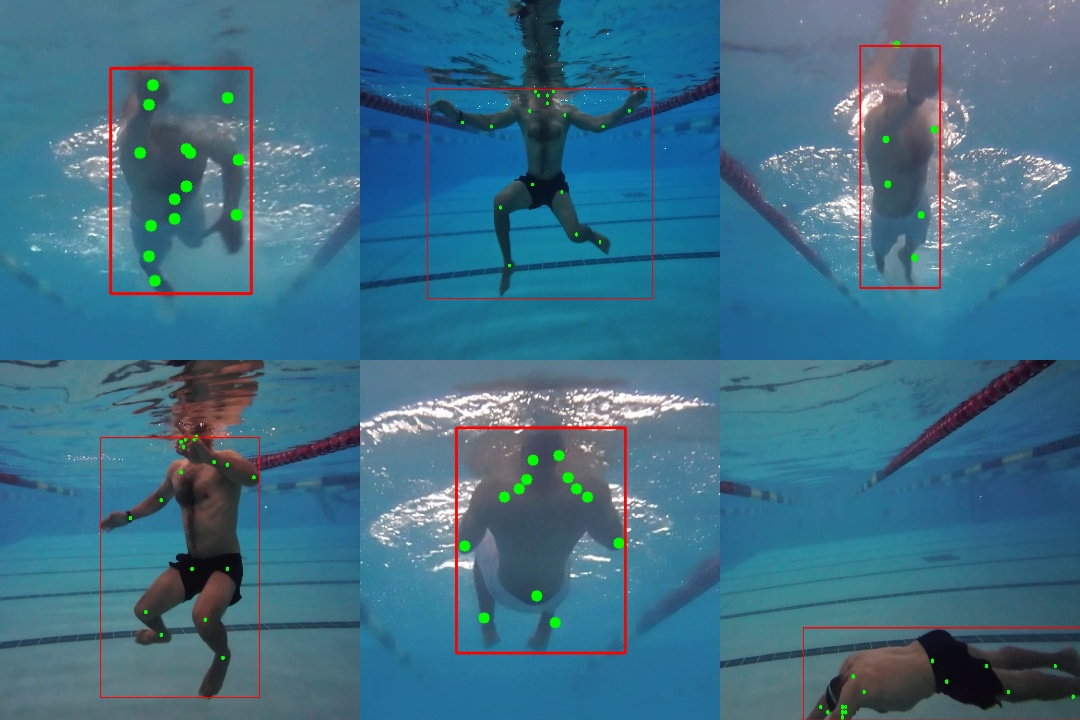

In [27]:
import json, cv2, numpy as np, random
from pathlib import Path
d = json.loads((SET / 'proposals_coco_keypoints.json').read_text())
names = {i['id']: i['file_name'] for i in d['images']}
sample = random.Random(0).sample(d['annotations'], 6)
tiles = []
for a in sample:
    im = cv2.imread(str(SET / 'images' / names[a['image_id']]))
    k = np.array(a['keypoints']).reshape(-1, 3)
    for x, y, v in k:
        if v > 0:
            cv2.circle(im, (int(x), int(y)), 6, (0, 255, 0), -1)
    x, y, w, h = [int(t) for t in a['bbox']]
    cv2.rectangle(im, (x, y), (x + w, y + h), (0, 0, 255), 2)
    cx, cy = x + w // 2, y + h // 2
    r = int(max(w, h) * 0.8)
    crop = im[max(0, cy - r):cy + r, max(0, cx - r):cx + r]
    tiles.append(cv2.resize(crop, (360, 360)))
sheet = np.vstack([np.hstack(tiles[:3]), np.hstack(tiles[3:])])
cv2.imwrite('/content/proposal_check.jpg', sheet)
from IPython.display import Image, display
display(Image('/content/proposal_check.jpg'))

## A8. Save the annotation set to Drive (download it from Drive for CVAT)

In [28]:
!cd /content && zip -qr "/content/drive/MyDrive/pose_annotation_set.zip" pose_annotation_set
print('saved: MyDrive/pose_annotation_set.zip')

saved: MyDrive/pose_annotation_set.zip


---
## Part B (only after the real_val frames are corrected in CVAT and exported)
Put the CVAT export (COCO Keypoints 1.0 JSON) on Drive and set `GT` below.

In [29]:
GT = Path('/content/drive/MyDrive/pose_gt_real_val.json')  # <- edit
assert GT.is_file(), f'Not found: {GT}'

AssertionError: Not found: /content/drive/MyDrive/pose_gt_real_val.json

In [30]:
!cd /content/pose_tools && python zero_shot_eval.py --gt "{GT}" --images "{SET}/images" --manifest "{SET}/manifest.csv" --split real_val --vitpose-onnx "{ONNX}" --yolo-pose yolo11s-pose.pt --out /content/drive/MyDrive/zero_shot_results.csv

Traceback (most recent call last):
  File "/content/pose_tools/zero_shot_eval.py", line 133, in <module>
    raise SystemExit(main())
                     ~~~~^^
  File "/content/pose_tools/zero_shot_eval.py", line 72, in main
    gt = load_gt(a.gt)
  File "/content/pose_tools/zero_shot_eval.py", line 28, in load_gt
    d = json.loads(coco_path.read_text(encoding="utf-8"))
                   ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/pathlib/_local.py", line 546, in read_text
    return PathBase.read_text(self, encoding, errors, newline)
           ~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/pathlib/_abc.py", line 632, in read_text
    with self.open(mode='r', encoding=encoding, errors=errors, newline=newline) as f:
         ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/pathlib/_local.py", line 537, in open
    return io.open(self, mode, buffering, encoding, errors, newline)


Paste the printed rows back. The COCO ViTPose-L baseline is not run here (no checkpoint chosen yet); add it once the SwimXYZ result is known.